# 02 · Benchmark: AI4I 2020 machine-failure classification

**Dataset.** *AI4I 2020 Predictive Maintenance Dataset* (Matzka, 2020), UCI Machine Learning Repository. It has 10,000 rows, one per production run of a milling machine: air and process temperature, rotational speed, torque, tool wear, and the product quality variant (L/M/H). The target is `Machine failure` (~3.4 % positive).

> **This is a simulated dataset.** The UCI page describes it as a *synthetic* dataset that reflects real predictive-maintenance data. Failures were generated by documented rules (tool wear, heat dissipation, power, overstrain) plus a small random-failure rate. Good scores here show a sound classification workflow on realistic, imbalanced data, not performance on a real factory.

**Task.** Predict `Machine failure` from the process measurements. The five failure-mode columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) say *which* failure happened, so they are excluded to avoid leakage. So are the row id (`UDI`) and `Product ID`.

**Citation.** S. Matzka, "Explainable Artificial Intelligence for Predictive Maintenance Applications," *2020 Third International Conference on Artificial Intelligence for Industries (AI4I)*, 2020, pp. 69–74. Dataset: [UCI ML Repository, id 601](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), doi:10.24432/C5HS5C (CC BY 4.0).

In [1]:
import json, sys, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
import plot_style as ps

ps.apply()
SEED = 42
DATA = ROOT / "data" / "ai4i2020"            # git-ignored download cache
OUT = ROOT / "results" / "benchmarks" / "ai4i2020"
URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

## 1. Download and load

In [2]:
DATA.mkdir(parents=True, exist_ok=True)
zip_path = DATA / "ai4i2020.zip"
if not zip_path.exists():
    urllib.request.urlretrieve(URL, zip_path)
with zipfile.ZipFile(zip_path) as z:
    raw = pd.read_csv(z.open("ai4i2020.csv"))

modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(f"{len(raw):,} rows · failure rate {raw['Machine failure'].mean():.2%}")
print("failures by mode:", raw[modes].sum().to_dict())
print("failures with no mode flagged:", int(((raw["Machine failure"] == 1) & (raw[modes].sum(axis=1) == 0)).sum()),
      "· mode flagged but no failure:", int(((raw["Machine failure"] == 0) & (raw[modes].sum(axis=1) > 0)).sum()))

10,000 rows · failure rate 3.39%
failures by mode: {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}
failures with no mode flagged: 9 · mode flagged but no failure: 18


## 2. Features

- **Raw**: product type, air and process temperature (K), rotational speed (rpm), torque (Nm), tool wear (min).
- **Engineered**: three physically meaningful combinations that the dataset documentation uses to describe its failure modes:
  - temperature difference (heat dissipation)
  - mechanical power = torque × angular speed (power failure)
  - tool wear × torque (overstrain)

  They are computed from the raw inputs only, so they don't leak the label. They do make the task easier, because they match the rules the simulator used. That's why both feature sets are reported.

In [3]:
df = raw.rename(columns={"Type": "type", "Air temperature [K]": "air_temp", "Process temperature [K]": "process_temp",
                         "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque", "Tool wear [min]": "tool_wear",
                         "Machine failure": "failure"})
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power_w"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_x_torque"] = df["tool_wear"] * df["torque"]

RAW = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]
ENG = RAW + ["temp_diff", "power_w", "wear_x_torque"]
y = df["failure"].values
assert not set(modes + ["UDI", "Product ID"]) & set(ENG + ["type"])  # no leakage columns

train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(train_idx):,} ({y[train_idx].sum()} failures) · test {len(test_idx):,} ({y[test_idx].sum()} failures)")

train 8,000 (271 failures) · test 2,000 (68 failures)


## 3. Models and imbalance handling

Three models plus a baseline. Each one handles the imbalance with **class weights**. Then, because the default 0.5 cut-off is arbitrary for a rare class, the **decision threshold** is chosen to maximise F1 on 5-fold *out-of-fold* predictions **inside the training set**. The test set is used exactly once, at the end.

- Logistic regression: scaled numeric features + one-hot type, `class_weight="balanced"`
- Random Forest: `class_weight="balanced_subsample"`
- Gradient boosting (`HistGradientBoostingClassifier`): `class_weight="balanced"`
- Baseline: always predicts the training failure rate (its PR-AUC equals the prevalence)

In [4]:
def make(name, num):
    if name == "Logistic regression":
        pre = ColumnTransformer([("num", StandardScaler(), num), ("type", OneHotEncoder(), ["type"])])
        return make_pipeline(pre, LogisticRegression(class_weight="balanced", max_iter=5000))
    pre = ColumnTransformer([("num", "passthrough", num),
                             ("type", OrdinalEncoder(categories=[["L", "M", "H"]]), ["type"])])
    if name == "Random Forest":
        return make_pipeline(pre, RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample",
                                                         n_jobs=-1, random_state=SEED))
    if name == "Gradient boosting":
        return make_pipeline(pre, HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, class_weight="balanced",
                                                                 random_state=SEED))
    return make_pipeline(pre, DummyClassifier(strategy="prior"))

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = int(np.nanargmax(f1[:-1])) if len(t) else 0
    return float(t[i]) if len(t) else 0.5

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
NAMES = ["Baseline (prior)", "Logistic regression", "Random Forest", "Gradient boosting"]
rows, curves, fitted = [], {}, {}
for fset, num in (("raw", RAW), ("raw + engineered", ENG)):
    Xtr, Xte = df.iloc[train_idx][num + ["type"]], df.iloc[test_idx][num + ["type"]]
    ytr, yte = y[train_idx], y[test_idx]
    for name in NAMES:
        oof = cross_val_predict(make(name, num), Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
        thr = best_f1_threshold(ytr, oof) if name != NAMES[0] else 0.5
        model = make(name, num).fit(Xtr, ytr)
        proba = model.predict_proba(Xte)[:, 1]
        pred = (proba >= thr).astype(int)
        rows.append({"features": fset, "model": name, "threshold": round(thr, 3),
                     "cv_pr_auc": round(average_precision_score(ytr, oof), 3),
                     "pr_auc": round(average_precision_score(yte, proba), 3),
                     "roc_auc": round(roc_auc_score(yte, proba), 3),
                     "f1": round(f1_score(yte, pred, zero_division=0), 3),
                     "precision": round(precision_score(yte, pred, zero_division=0), 3),
                     "recall": round(recall_score(yte, pred), 3)})
        curves[(fset, name)] = precision_recall_curve(yte, proba)[:2]
        fitted[(fset, name)] = (model, thr, pred)

res = pd.DataFrame(rows)
res.set_index(["features", "model"])

threshold  cv_pr_auc  pr_auc  roc_auc  \
features         model                                                        
raw              Baseline (prior)         0.500      0.034   0.034    0.500   
                 Logistic regression      0.879      0.432   0.382    0.907   
                 Random Forest            0.334      0.757   0.791    0.969   
                 Gradient boosting        0.564      0.789   0.845    0.966   
raw + engineered Baseline (prior)         0.500      0.034   0.034    0.500   
                 Logistic regression      0.922      0.455   0.430    0.939   
                 Random Forest            0.419      0.894   0.875    0.978   
                 Gradient boosting        0.713      0.885   0.901    0.983   

                                         f1  precision  recall  
features         model                                          
raw              Baseline (prior)     0.000      0.000   0.000  
                 Logistic regression  0.373      0.379   0.368  
                 Random Forest        0.712      0.667   0.765  
                 Gradient boosting    0.773      0.797   0.750  
raw + engineered Baseline (prior)     0.000      0.000   0.000  
                 Logistic regression  0.435      0.532   0.368  
                 Random Forest        0.875      0.933   0.824  
                 Gradient boosting    0.905      0.983   0.838

`cv_pr_auc` is measured on the training folds and is what a model would be **chosen** by. All the other columns are on the untouched test set (2,000 rows, 68 failures). PR-AUC is the headline metric: with 3.4 % positives, ROC-AUC looks flattering even for weak models, while PR-AUC starts from a baseline equal to the prevalence (~0.034).

In [5]:
best = res[res["model"] != NAMES[0]].sort_values("cv_pr_auc", ascending=False).iloc[0]
key = (best["features"], best["model"])
model, thr, pred = fitted[key]
cm = confusion_matrix(y[test_idx], pred)
print(f"selected by training-CV PR-AUC: {best['model']} ({best['features']}) · threshold {thr:.3f}")
print(f"test: PR-AUC {best['pr_auc']} · F1 {best['f1']} · precision {best['precision']} · recall {best['recall']}")
pd.DataFrame(cm, index=["actual: no failure", "actual: failure"], columns=["predicted: no failure", "predicted: failure"])

selected by training-CV PR-AUC: Random Forest (raw + engineered) · threshold 0.419
test: PR-AUC 0.875 · F1 0.875 · precision 0.933 · recall 0.824


,predicted: no failure,predicted: failure
actual: no failure,1928,4
actual: failure,12,56


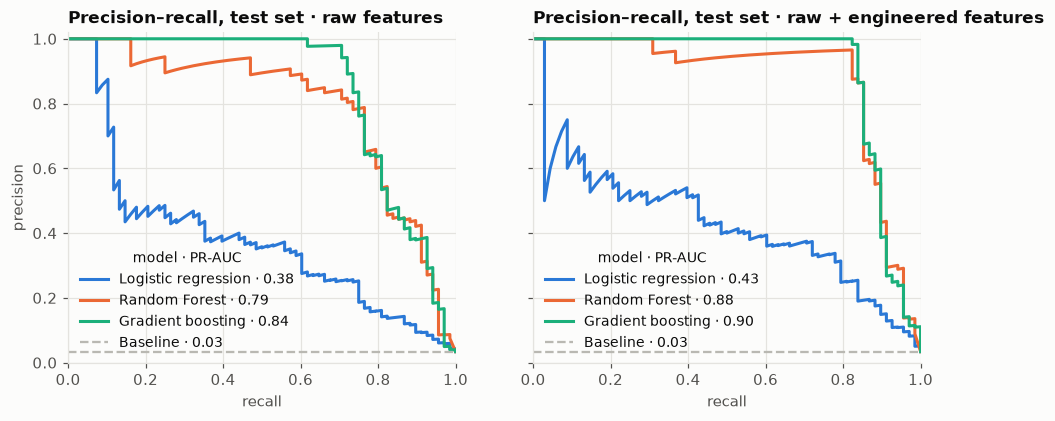

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
prevalence = y[test_idx].mean()
for ax, fset in zip(axes, ("raw", "raw + engineered")):
    for color, name in zip(ps.SERIES, NAMES[1:]):
        p, r = curves[(fset, name)]
        ap = res.query("features == @fset and model == @name")["pr_auc"].item()
        ax.plot(r, p, color=color, label=f"{name} · {ap:.2f}")
    ax.axhline(prevalence, color=ps.NEUTRAL, lw=1.5, ls="--", label=f"Baseline · {prevalence:.2f}")
    ax.set(title=f"Precision–recall, test set · {fset} features", xlabel="recall", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="lower left", title="model · PR-AUC", title_fontsize=9, fontsize=9)
axes[0].set_ylabel("precision")
ps.save(fig, OUT / "pr_curves.png")

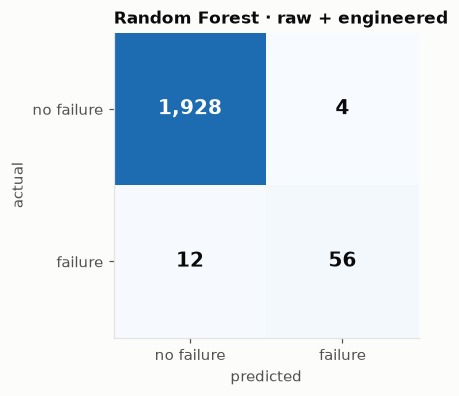

In [7]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.3)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=13, fontweight="bold",
            color="white" if v > cm.max() / 2 else ps.TEXT)
ax.set_xticks([0, 1], ["no failure", "failure"]); ax.set_yticks([0, 1], ["no failure", "failure"])
ax.set(xlabel="predicted", ylabel="actual", title=f"{best['model']} · {best['features']}")
ax.grid(False)
ps.save(fig, OUT / "confusion_matrix.png")

## 4. What the errors look like

Which failure modes does the selected model miss on the test set? Random failures (`RNF`) are random by design, so no model should catch them.

In [8]:
test = df.iloc[test_idx].assign(pred=pred)
missed = test[(test["failure"] == 1) & (test["pred"] == 0)]
caught = test[(test["failure"] == 1) & (test["pred"] == 1)]
pd.DataFrame({"caught": caught[modes].sum(), "missed": missed[modes].sum()}).T

,TWF,HDF,PWF,OSF,RNF
caught,1,28,13,16,0
missed,9,1,0,0,0


## 5. Save results

In [9]:
OUT.mkdir(parents=True, exist_ok=True)
summary = {
    "dataset": "AI4I 2020 Predictive Maintenance Dataset (UCI id 601) — simulated",
    "citation": "S. Matzka, 'Explainable Artificial Intelligence for Predictive Maintenance Applications', AI4I 2020, pp. 69-74. doi:10.24432/C5HS5C",
    "url": "https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset",
    "task": "binary classification of 'Machine failure'; failure-mode columns, UDI and Product ID excluded",
    "rows": int(len(df)), "failure_rate": round(float(y.mean()), 4),
    "split": "stratified 80/20, seed 42; thresholds tuned for F1 on 5-fold out-of-fold training predictions",
    "test_rows": int(len(test_idx)), "test_failures": int(y[test_idx].sum()),
    "results": rows,
    "selected": {"features": best["features"], "model": best["model"], "threshold": round(thr, 3),
                 "confusion_matrix": {"tn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "tp": int(cm[1, 1])}},
    "figures": ["pr_curves.png", "confusion_matrix.png"],
}
(OUT / "metrics.json").write_text(json.dumps(summary, indent=2))
print("saved", sorted(p.name for p in OUT.iterdir()))

saved ['confusion_matrix.png', 'metrics.json', 'pr_curves.png']


## 6. Takeaways

- **Class weights plus a tuned threshold** turn a 3.4 %-positive problem into a usable detector. The "always no failure" model would be 96.6 % *accurate* and useless, which is why accuracy isn't reported.
- **Tree ensembles beat logistic regression by a wide margin** (PR-AUC ≈ 0.8–0.9 vs ≈ 0.4). The simulator's failure rules are thresholds, and some are non-monotonic: a power failure happens when power is either *too low or too high*. A single linear boundary can't express "outside a band", even with the engineered features.
- **Domain features help the trees a lot.** Adding temperature difference, power and wear × torque lifts both ensembles by about 0.05–0.1 PR-AUC. Knowing how the machine fails matters as much as the choice of algorithm.
- **Model selection used training-CV only.** Random Forest edged out gradient boosting on CV PR-AUC, so it is the reported model, even though gradient boosting scores slightly higher on the test set. Picking by the test set would overstate performance.
- **Honest limits.** The data is simulated with known rules, so near-perfect separation is possible in principle. Real machines have messier signals, label noise and drift.